# Post 1: training the CNN on CIFAR-10

The same model as `01_data_and_pipeline.ipynb`, on CIFAR-10: 32x32 colour photos
instead of 28x28 grey digits. Without help this model overfits badly, so this
notebook adds data augmentation and weight decay. It needs a 160 MB download on
first use.

## Setup

On Colab this clones the repo and installs it with the `posts` extra. Locally
(`uv run jupyter lab`, or VS Code with the repo's `.venv`) it does nothing.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !git clone --depth 1 https://github.com/anujkhare/toylib.git /content/toylib
    %cd /content/toylib
    !pip install -q -e ".[posts]"

In [2]:
import pathlib
import shutil

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from absl import logging as absl_logging

from toylib import viz
from toylib.harness import analyze, inference
from toylib.harness.experiment import (
    CheckpointConfig,
    EvalConfig,
    Experiment,
    LoggerConfig,
    MultiOptimizerConfig,
    OptimizerConfig,
    Task,
    TrainingConfig,
)
from toylib.harness.metrics import Loss
from toylib_projects.p01_cnn_mnist import data, metrics, model

DATASET = "cifar10"
BATCH_SIZE = 128
EPOCHS = 40
WEIGHT_DECAY = 0.1

absl_logging.set_verbosity(absl_logging.ERROR)  # quiet orbax's read-only notices
viz.use_style()
info = data.DATASETS[DATASET]
print("JAX devices:", jax.devices())

JAX devices: [CpuDevice(id=0)]


## 1. Load the data

`make_datasets` downloads once (cached under `~/.cache/toylib`), scales pixels
to zero mean and unit variance per channel, and wraps the arrays in
`ArrayDataset`: shuffled fixed-size batches for training, a fixed order for test.
`augment=True` flips and shifts each training image at random, so the model
rarely sees exactly the same picture twice. Test images are left alone.

In [3]:
train_ds, test_ds = data.make_datasets(DATASET, batch_size=BATCH_SIZE, eval_batch_size=500, augment=True)

for split, ds in [("train", train_ds), ("test", test_ds)]:
    x, y = ds.arrays["image"], ds.arrays["label"]
    print(f"{split:5s} image {x.shape} {x.dtype}  label {y.shape} {y.dtype}  "
          f"{ds.batches_per_epoch} batches of {ds.batch_size}")
print("train label counts:", np.bincount(train_ds.arrays["label"]))
print(f"train pixel mean {train_ds.arrays['image'].mean():.3f}, std {train_ds.arrays['image'].std():.3f}")

train image (50000, 32, 32, 3) float32  label (50000,) int32  390 batches of 128
test  image (10000, 32, 32, 3) float32  label (10000,) int32  20 batches of 500
train label counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
train pixel mean -0.000, std 1.000


## 2. A few batches

Iterating a dataset yields dicts of NumPy arrays. Pixel statistics per batch
should hover around mean 0 and std 1.

In [4]:
import einops

batch 0: image (128, 32, 32, 3) float32, label (128,) int32  | mean -0.003 std 0.884
batch 1: image (128, 32, 32, 3) float32, label (128,) int32  | mean -0.022 std 0.932
batch 2: image (128, 32, 32, 3) float32, label (128,) int32  | mean -0.011 std 0.936


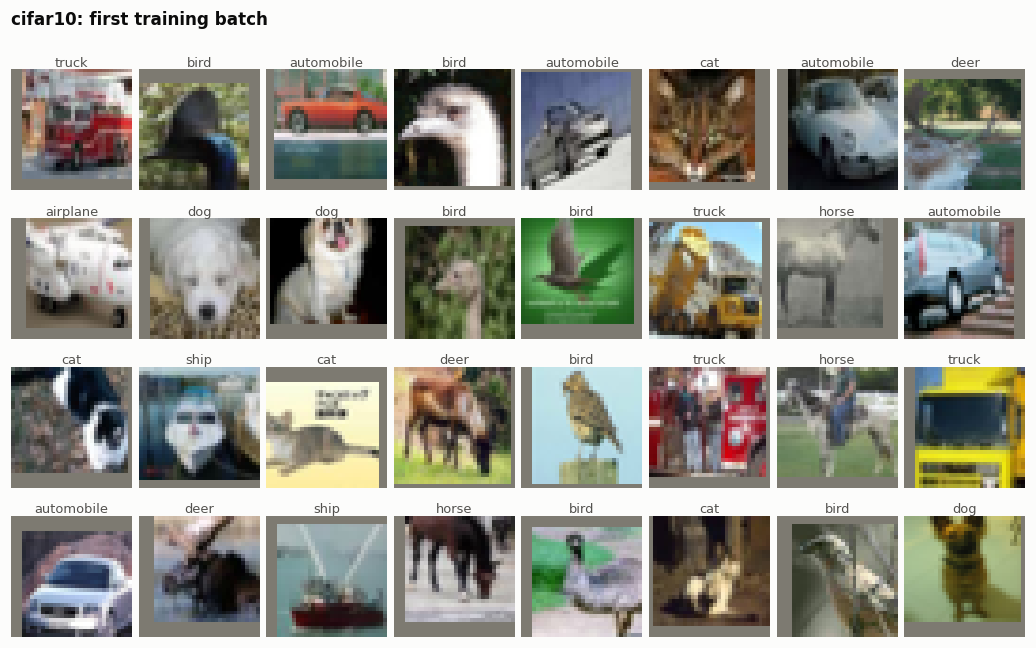

In [5]:
batches = []
for i, batch in zip(range(3), train_ds):
    batches.append(batch)
    print(f"batch {i}: " + ", ".join(f"{k} {v.shape} {v.dtype}" for k, v in batch.items())
          + f"  | mean {batch['image'].mean():+.3f} std {batch['image'].std():.3f}")

batch = batches[0]
fig = viz.image_grid(
    data.unpreprocess(batch["image"][:32], info),
    titles=[info.class_names[int(c)] for c in batch["label"][:32]],
    suptitle=f"{DATASET}: first training batch",
)

In [6]:
print(batch['image'].shape)

(128, 32, 32, 3)


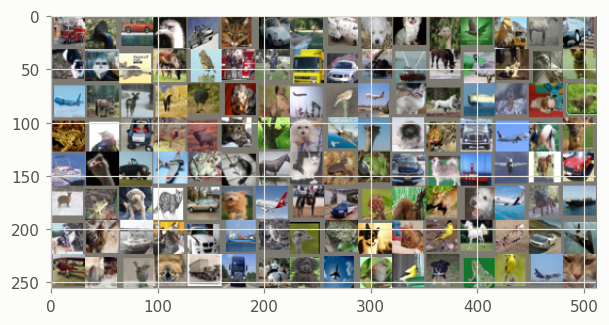

In [7]:
plt.imshow(einops.rearrange(data.unpreprocess(batch['image'], info), '(x y) h w c -> (x h) (y w) c', x=8, y=16))

## 3. The model

`build_model` is the harness's `model_factory`. The shape trace calls each block
in turn; compare it with your hand calculation.

In [8]:
config = model.ModelConfig(image_shape=info.image_shape, num_classes=len(info.class_names))
net = model.build_model(config, jax.random.key(0))

x = jnp.asarray(batch["image"])
print("input  ", x.shape)
for name in ["conv1", "conv2", "conv3"]:
    x = getattr(net, name)(x)
    print(f"{name:7s}", x.shape)
print("logits ", net(batch["image"]).shape)

table, n_params, n_bytes = analyze.print_param_sizes(net, depth=1)
table

input   (128, 32, 32, 3)
conv1   (128, 16, 16, 32)
conv2   (128, 8, 8, 64)
conv3   (128, 8, 8, 64)


logits  (128, 10)
Total Parameters: 97,290. Bytes: (389,160.00)


,level_0,dtype,params,n_bytes_divided
0,.conv1,float32,896,3584.0
1,.conv2,float32,18496,73984.0
2,.conv3,float32,36928,147712.0
3,.head,float32,40970,163880.0


## 4. Overfit one batch

One loss and gradient evaluation, then 50 jitted Adam steps on a single batch.
The first loss should be close to ln(10) = 2.303, and the loss on the repeated
batch should fall towards zero.

In [9]:
loss, aux = model.forward(net, batch)
grads = jax.grad(lambda m: model.forward(m, batch)[0])(net)
print("loss", float(loss), "| accuracy", float(metrics.Accuracy()(loss, aux, batch)["accuracy"]))
print("grad norms:", {jax.tree_util.keystr(p): float(jnp.linalg.norm(g))
                      for p, g in jax.tree_util.tree_leaves_with_path(grads)})


optimizer = optax.adam(1e-3)


@jax.jit
def train_step(m, opt_state, b):
    loss, g = jax.value_and_grad(lambda m: model.forward(m, b)[0])(m)
    updates, opt_state = optimizer.update(g, opt_state, m)
    return optax.apply_updates(m, updates), opt_state, loss


m, opt_state = net, optimizer.init(net)
for step in range(50):
    m, opt_state, loss = train_step(m, opt_state, batch)
    if step % 10 == 0 or step == 49:
        print(f"step {step}: loss {float(loss):.4f}")

loss 2.3026740550994873 | accuracy 0.0859375


grad norms: {'.conv1.conv_layer.weights': 0.009270979091525078, '.conv1.conv_layer.bias': 0.001677267369814217, '.conv2.conv_layer.weights': 0.03189951181411743, '.conv2.conv_layer.bias': 0.0022360975854098797, '.conv3.conv_layer.weights': 0.052214208990335464, '.conv3.conv_layer.bias': 0.003421214409172535, '.head.weights': 2.4316482543945312, '.head.bias': 0.08871224522590637}


step 0: loss 2.3027


step 10: loss 0.7916


step 20: loss 0.1912


step 30: loss 0.0320


step 40: loss 0.0059


step 49: loss 0.0023


## 5. Train through `Experiment`

The same `model_factory` and `forward_fn`, now driven by the harness: jitted
train steps, evaluation on the whole test set and a checkpoint after every epoch,
and a JSON-lines log. Outputs go to `toylib_projects/p01_cnn_mnist/outputs/`
(gitignored), and the run directory is wiped first so re-running starts clean.

The optimizer is AdamW with cosine learning-rate decay. Each change below was a
separate run of the same model; the first row trained on 20 epochs, the others on 40.

| Setup | Final test accuracy | Train accuracy |
| --- | --- | --- |
| Adam, no augmentation | 72.1% | 95.6% |
| Augmentation | 81.3% | 82.2% |
| Augmentation, AdamW `weight_decay=0.01`, cosine | 82.2% | 82.5% |
| Augmentation, AdamW `weight_decay=0.1`, cosine | 82.4% | 82.7% |

These were scratch runs. The run saved in this notebook, with the same settings, reached 81.9%, which shows how much a single run varies: about a point.

Train and test accuracy now match, so this model is no longer overfitting: it is
limited by capacity, not memorization.

In [10]:
%%time
out_dir = (pathlib.Path(model.__file__).parent / "outputs" / f"notebook_{DATASET}").resolve()
shutil.rmtree(out_dir, ignore_errors=True)

steps_per_epoch = train_ds.batches_per_epoch
total_steps = EPOCHS * steps_per_epoch
learning_rate = optax.cosine_decay_schedule(1e-3, total_steps)
optimizer_config = MultiOptimizerConfig(
    [OptimizerConfig("adamw", optax.adamw(learning_rate, weight_decay=WEIGHT_DECAY))],
    optimizer_for_param=lambda path: "adamw",
)
task_metrics = [Loss(), metrics.Accuracy()]
exp = Experiment(
    train_task=Task("train", train_ds, metrics=task_metrics),
    eval_task=Task("test", test_ds, metrics=task_metrics),
    model_factory=model.build_model,
    forward_fn=model.forward,
    model_config=config,
    # +1: the harness evaluates and saves a step before counting it, so this
    # makes the last epoch's evaluation and checkpoint happen.
    training_config=TrainingConfig(optimizer_config=optimizer_config, max_steps=total_steps + 1),
    eval_config=EvalConfig(eval_interval_steps=steps_per_epoch, num_eval_steps=test_ds.batches_per_epoch),
    checkpoint_config=CheckpointConfig(save_interval_steps=steps_per_epoch, max_to_keep=None, checkpoint_dir=str(out_dir / "checkpoints")),
    logger_config=LoggerConfig(log_dir=str(out_dir), run_id="train", train_log_interval_steps=50),
)
exp.init_state()
exp.outer_loop()
exp.cleanup()

Initialized mesh Mesh('data': 1, axis_types=(Auto,)) with 1 devices: [CpuDevice(id=0)]


Model initialized and replicated across 1 devices


CPU times: user 40min 29s, sys: 7min 22s, total: 47min 51s
Wall time: 8min 24s


epoch  0.0: test loss 2.4196, test accuracy 0.1023
epoch  1.0: test loss 1.1604, test accuracy 0.5897
epoch  2.0: test loss 0.9877, test accuracy 0.6533
epoch  3.0: test loss 0.9421, test accuracy 0.6772
epoch  4.0: test loss 0.8145, test accuracy 0.7163
epoch  5.0: test loss 0.7744, test accuracy 0.7296
epoch  6.0: test loss 0.7652, test accuracy 0.7354
epoch  7.0: test loss 0.7531, test accuracy 0.7470
epoch  8.0: test loss 0.7180, test accuracy 0.7552
epoch  9.0: test loss 0.7065, test accuracy 0.7548
epoch 10.0: test loss 0.6904, test accuracy 0.7633
epoch 11.0: test loss 0.6753, test accuracy 0.7675
epoch 12.0: test loss 0.6713, test accuracy 0.7692
epoch 13.0: test loss 0.6742, test accuracy 0.7642
epoch 14.0: test loss 0.6258, test accuracy 0.7845
epoch 15.0: test loss 0.6350, test accuracy 0.7816
epoch 16.0: test loss 0.6154, test accuracy 0.7885
epoch 17.0: test loss 0.6191, test accuracy 0.7877
epoch 18.0: test loss 0.6134, test accuracy 0.7871
epoch 19.0: test loss 0.5899, t

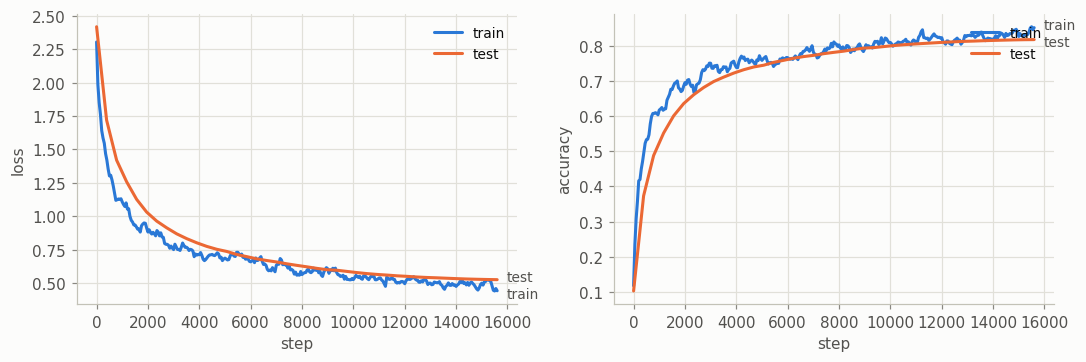

In [11]:
log_path = out_dir / "logs_train.txt"
curves = viz.read_log(log_path)

steps, val_acc = curves["val/accuracy"]
_, val_loss = curves["val/loss"]
for step, loss_value, accuracy in zip(steps, val_loss, val_acc):
    print(f"epoch {step / steps_per_epoch:4.1f}: test loss {loss_value:.4f}, test accuracy {accuracy:.4f}")


def train_vs_test(name):
    return {"train": {name: curves[f"train/{name}"]}, "test": {name: curves[f"val/{name}"]}}


fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
viz.plot_curves(train_vs_test("loss"), "loss", smoothing=0.8, ax=axes[0])
viz.plot_curves(train_vs_test("accuracy"), "accuracy", smoothing=0.8, ax=axes[1])
fig.tight_layout()

## 6. Test the trained model

Restores the latest checkpoint into a fresh model and runs it over the whole test
set in batches: overall accuracy, accuracy per class, the confusion matrix, and
the test images the model got most wrong. This is what `figures.py` will do later.

In [12]:
steps = inference.checkpoint_steps(out_dir / "checkpoints")
print("checkpoints at steps", steps)

images, labels = test_ds.arrays["image"], test_ds.arrays["label"]
restored = inference.load_model(model.build_model(config, jax.random.key(1)), out_dir / "checkpoints")
test_logits = inference.batched_apply(lambda m, b: m(b["image"]), restored, {"image": images}, 500)
predictions = test_logits.argmax(-1)
test_acc = float(np.mean(predictions == labels))
print(f"test logits {test_logits.shape}, accuracy {test_acc:.4f} ({int((predictions != labels).sum())} wrong)")

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (labels, predictions), 1)
for name, row, total in zip(info.class_names, np.diag(confusion), confusion.sum(axis=1)):
    print(f"{name:12s} {row / total:.3f}")

checkpoints at steps [0, 390, 780, 1170, 1560, 1950, 2340, 2730, 3120, 3510, 3900, 4290, 4680, 5070, 5460, 5850, 6240, 6630, 7020, 7410, 7800, 8190, 8580, 8970, 9360, 9750, 10140, 10530, 10920, 11310, 11700, 12090, 12480, 12870, 13260, 13650, 14040, 14430, 14820, 15210, 15600]


test logits (10000, 10), accuracy 0.8191 (1809 wrong)
airplane     0.845
automobile   0.906
bird         0.741
cat          0.650
deer         0.827
dog          0.734
frog         0.866
horse        0.839
ship         0.898
truck        0.885


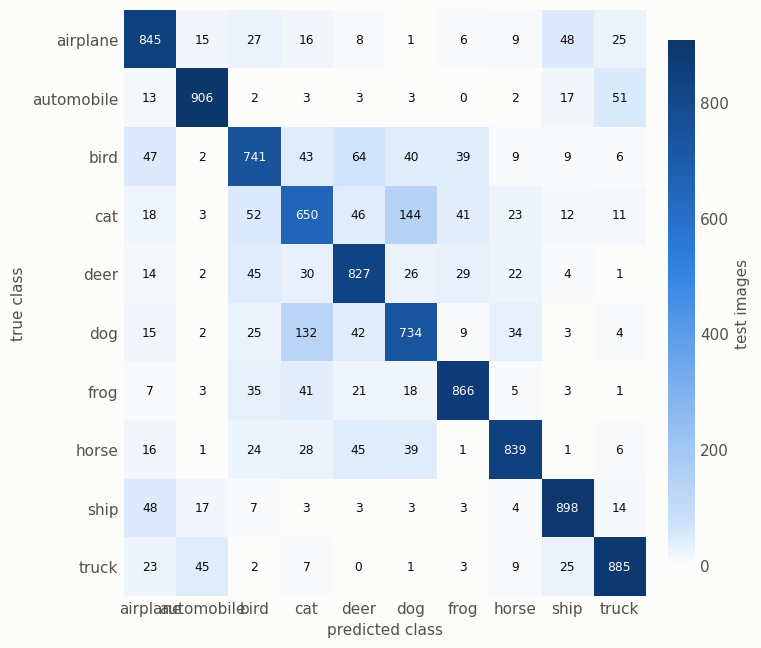

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
viz.heatmap(confusion, row_labels=info.class_names, col_labels=info.class_names,
            annotate=True, fmt="{:.0f}", colorbar_label="test images", ax=ax)
ax.set_ylabel("true class")
ax.set_xlabel("predicted class")
fig.tight_layout()

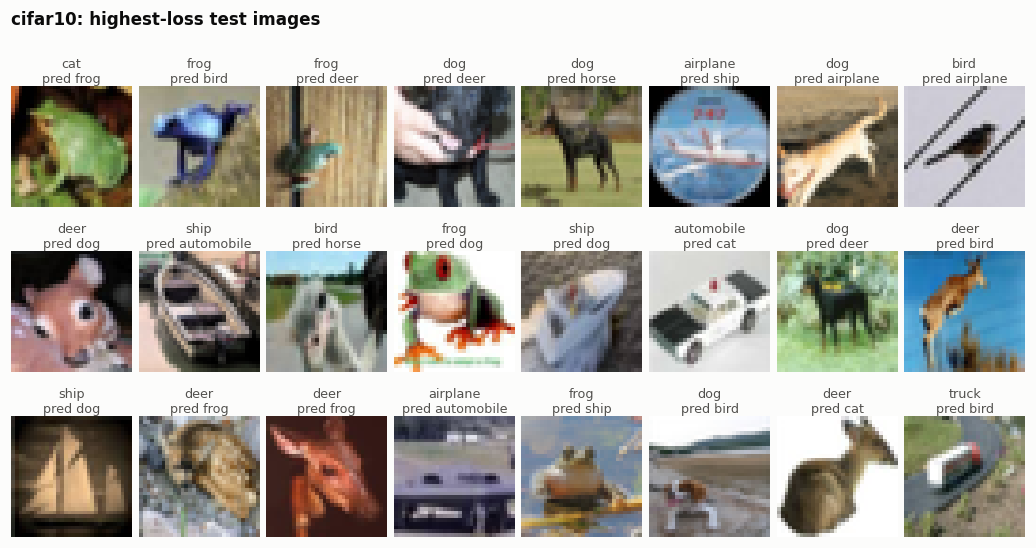

In [14]:
per_example_loss = np.asarray(
    optax.softmax_cross_entropy_with_integer_labels(jnp.asarray(test_logits), jnp.asarray(labels))
)
worst = np.argsort(per_example_loss)[::-1][:24]
fig = viz.image_grid(
    data.unpreprocess(images[worst], info),
    titles=[f"{info.class_names[labels[i]]}\npred {info.class_names[predictions[i]]}" for i in worst],
    suptitle=f"{DATASET}: highest-loss test images",
)

## Next

`resnet.py` adds residual blocks and depth, since this model has run out of
capacity rather than data.